# EXP-0001-R3 / EXP-0001-R2 — Driver-Only Pairwise Elo Baseline (Outcome-Independent)

**Experiment ID:** `EXP-0001-R3` (referencing `EXP-0001-R2` and `EXP-0001-R1`)  
**Model Family:** Latent Rating / Pairwise Elo Walk-Forward  
**Hypothesis Reference:** [HYP-0001: Sequential Information Superiority](../docs/research/HYPOTHESES.md#hyp-0001-sequential-information-superiority)  
**Primary Checkpoint:** $T_0$ (Pre-Weekend / Static Baseline)  
**Evaluation Protocol:** Chronological Walk-Forward (2010–2026, 346 races)  
**Dataset:** `data/interim/driver_race_results_2010_2026_v2_regulation_metadata.csv` (7,285 rows)  

---

## 1. Context & Research Objectives

This notebook implements the corrected benchmark run for the driver-only Elo race-winner model across 2010–2026.

### Version Evolution & Methodological Progression:
- **EXP-0001-R1 (Initial Exploratory Run):** 346 races. Log loss: 2.275307, Brier: 0.844919, Legacy argmax top-1: 0.332370. Retrospective candidate field without serialized candidate distributions; non-starters skipped only for codes W.
- **EXP-0001-R2 (Non-Starter & Full Distribution Run):** 346 races. Log loss: 2.278177, Brier: 0.845726, Tie-aware top-1: 0.335260, Fractional credit: 0.332490. Excluded explicit non-starters and disqualified entrants (72 skips audited). Preserved in `artifacts/reports/EXP-0001-R2/`.
  - *Audit Finding:* In R2, candidates were sorted by `finish_position_int` before forecasting. In 2010 Round 1 (a 24-way tie at 1500.0), `np.argmax` selected index 0 (Alonso), which artificially gave `legacy_top1` a hit using post-race finishing position order.
- **EXP-0001-R3 (Strict Outcome-Independent Candidate Ordering):** Enforces strictly pre-race outcome-independent candidate ordering (`driver_id` sort). Preserved in `artifacts/reports/EXP-0001-R3/`:
  - Log loss: 2.278177, Brier: 0.845726 (identical to R2).
  - Tie-aware top-1: 0.335260 (116 / 346).
  - Fractional credit: 0.332490 (115.0417 / 346).
  - Legacy argmax top-1: 0.332370 (115 / 346, exposing the arbitrary tie-break effect).

### Information Cutoff & Retrospective Limitation
> **Methodological Limitation:** The candidate field is reconstructed from historical race-result records. In races where a driver was entered but did not start (DNS/Withdrew), the candidate field retrospectively includes them in the pre-race candidate pool. While they are excluded from post-race rating updates, a future milestone (M2 pre-race entry list reconstruction) will tighten this boundary to true pre-race entry lists.

In [9]:
# 1. Environment Setup & Robust Project-Root Discovery
import os
import sys
import math
import json
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Robust project-root discovery by searching parent directories for markers
current_path = Path.cwd().resolve()
project_root = None

for candidate in [current_path] + list(current_path.parents):
    if (candidate / "AGENTS.md").is_file() and (candidate / "README.md").is_file():
        project_root = candidate
        break

if project_root is None:
    raise FileNotFoundError(
        f"Could not locate project root containing AGENTS.md and README.md from {current_path}"
    )

print(f"Project root discovered: {project_root}")
print(f"Python executable: {sys.executable}")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

Project root discovered: /Users/dhruv/dhruv files/apex-f1
Python executable: /opt/anaconda3/bin/python
Pandas version: 2.2.2
NumPy version: 1.26.4


In [2]:
# 2. Experiment Configuration & Hyperparameters
EXPERIMENT_ID = "EXP-0001-R3"
DATA_PATH = project_root / "data/interim/driver_race_results_2010_2026_v2_regulation_metadata.csv"
OUTPUT_DIR = project_root / "artifacts/reports/EXP-0001-R3"
PREVIOUS_RUN_DIRS = {
    "R1": project_root / "artifacts/reports/EXP-0001",
    "R2": project_root / "artifacts/reports/EXP-0001-R2",
}

# Hyperparameters (Standard Elo configuration)
INITIAL_RATING = 1500.0
ELO_SCALE = 400.0
K_FACTOR = 20.0

# Ensure output directory exists
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Target dataset: {DATA_PATH.relative_to(project_root)}")
print(f"Output directory: {OUTPUT_DIR.relative_to(project_root)}")
print(f"Initial rating (R0): {INITIAL_RATING}")
print(f"Elo scale factor (S): {ELO_SCALE}")
print(f"K-factor: {K_FACTOR}")

Target dataset: data/interim/driver_race_results_2010_2026_v2_regulation_metadata.csv
Output directory: artifacts/reports/EXP-0001-R2
Initial rating (R0): 1500.0
Elo scale factor (S): 400.0
K-factor: 20.0


In [3]:
# 3. Load & Validate Dataset with Strict Chronological Ordering
assert DATA_PATH.is_file(), f"Dataset missing at: {DATA_PATH}"

df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df_raw)} records across {df_raw['season'].nunique()} seasons ({df_raw['season'].min()}–{df_raw['season'].max()}).")

# Assert required columns exist
required_cols = [
    "season", "round", "race_date", "race_name", "circuit_id",
    "driver_id", "driver_name", "finish_position", "position_text",
    "status", "regulation_era"
]
missing_cols = [c for c in required_cols if c not in df_raw.columns]
assert not missing_cols, f"Missing required columns: {missing_cols}"

# Ensure clean numeric types for sorting
df_raw["season_int"] = df_raw["season"].astype(int)
df_raw["round_int"] = df_raw["round"].astype(int)
df_raw["finish_position_int"] = df_raw["finish_position"].astype(int)

# CRITICAL METHODOLOGICAL INTEGRITY:
# Sort chronologically by season and round, but order candidates within each race
# by driver_id (pre-race identifier) rather than finish_position_int to guarantee
# candidate ordering is strictly independent of the observed post-race outcome.
df_sorted = df_raw.sort_values(
    by=["season_int", "round_int", "race_date", "driver_id"]
).reset_index(drop=True)

# Check that every race has exactly one winner (finish_position == 1)
race_winners = df_sorted[df_sorted["finish_position_int"] == 1].groupby(["season_int", "round_int"]).size()
assert (race_winners == 1).all(), "Integrity Error: Found races without exactly one winner!"
total_races = len(race_winners)
print(f"Verified {total_races} chronologically sorted races with valid single winners.")

Loaded 7285 records across 17 seasons (2010–2026).
Verified 346 chronologically sorted races with valid single winners.


In [4]:
# 4. Helper Functions: Rating Exclusion & Probabilistic Calculations

def is_excluded_from_rating_update(row):
    """
    Determine whether a candidate should be excluded from post-race Elo updates.
    
    Policy:
    - Exclude explicit non-starters, withdrawals, failed qualifiers, and disqualified drivers.
    - Keep retired drivers and classified finishers in the rating update set.
    """
    status = str(row.get("status", "")).strip().lower()
    pos_text = str(row.get("position_text", "")).strip().upper()

    # Code checks
    if pos_text in ("W", "F", "D", "DNS", "DNQ", "DSQ", "EXC"):
        return True, f"pos_code_{pos_text}"

    # Text keyword checks
    exclusion_keywords = [
        "did not start",
        "withdrew",
        "failed to qualify",
        "did not qualify",
        "disqualified",
        "excluded",
    ]
    for kw in exclusion_keywords:
        if kw in status:
            return True, f"status_{kw}"

    return False, "eligible_starter"

def compute_bradley_terry_win_probabilities(ratings, scale=ELO_SCALE):
    """
    Compute normalized multiclass win probabilities using Bradley-Terry / Luce softmax:
    P_i = 10^(R_i / Scale) / sum_m 10^(R_m / Scale)
    """
    ratings_arr = np.array(ratings, dtype=float)
    # Stabilize softmax using max-subtraction in exponent
    max_r = np.max(ratings_arr)
    unnorm = 10.0 ** ((ratings_arr - max_r) / scale)
    probs = unnorm / np.sum(unnorm)
    return probs

In [5]:
# 5. Elo Baseline Simulation: Chronological Walk-Forward Loop

driver_ratings = defaultdict(lambda: INITIAL_RATING)

candidate_prediction_records = []
race_prediction_records = []
rating_audit_records = []

race_groups = df_sorted.groupby(["season_int", "round_int", "race_date", "race_name"], sort=False)

for (season, rnd, r_date, r_name), race_df in race_groups:
    candidates = race_df.to_dict("records")
    n_candidates = len(candidates)
    circuit_id = candidates[0].get("circuit_id", "")
    regulation_era = candidates[0].get("regulation_era", "")

    # 1. Fetch pre-race ratings
    pre_race_ratings = [driver_ratings[c["driver_id"]] for c in candidates]

    # 2. Compute candidate win probabilities
    win_probs = compute_bradley_terry_win_probabilities(pre_race_ratings, scale=ELO_SCALE)
    
    # Explicit assertion: verify probabilities sum to 1.0 within numerical tolerance
    assert np.isclose(np.sum(win_probs), 1.0, atol=1e-5), (
        f"Probability normalization failure at {season} Round {rnd}: sum={np.sum(win_probs)}"
    )

    # 3. Locate actual winner
    winner_indices = [idx for idx, c in enumerate(candidates) if c["finish_position_int"] == 1]
    assert len(winner_indices) == 1, f"Expected single winner in {season} R{rnd}, found {len(winner_indices)}"
    winner_idx = winner_indices[0]
    winner_cand = candidates[winner_idx]
    winner_prob = win_probs[winner_idx]

    # 4. Tie-aware top-1 identification
    max_prob = np.max(win_probs)
    tied_indices = np.where(np.isclose(win_probs, max_prob, atol=1e-7))[0]
    n_tied = len(tied_indices)
    has_top_tie = (n_tied > 1)

    # Metrics under ties
    tie_aware_top1_hit = 1.0 if (winner_idx in tied_indices) else 0.0
    fractional_top1_credit = (1.0 / n_tied) if (winner_idx in tied_indices) else 0.0

    # Legacy argmax (arbitrary first index)
    legacy_argmax_idx = int(np.argmax(win_probs))
    legacy_top1_correct = (winner_idx == legacy_argmax_idx)

    # 5. Scoring calculations
    elo_log_loss = -float(np.log(max(winner_prob, 1e-15)))
    unif_prob = 1.0 / n_candidates
    unif_log_loss = -float(np.log(unif_prob))

    # Multiclass Brier score: sum_m (P_m - Y_m)^2
    y_true = np.zeros(n_candidates)
    y_true[winner_idx] = 1.0
    elo_brier = float(np.sum((win_probs - y_true) ** 2))
    unif_brier = float((1.0 - unif_prob) ** 2 + (n_candidates - 1) * (unif_prob ** 2))

    # 6. Save candidate-level records
    for idx, c in enumerate(candidates):
        candidate_prediction_records.append({
            "season": season,
            "round": rnd,
            "race_date": r_date,
            "race_name": r_name,
            "circuit_id": circuit_id,
            "driver_id": c["driver_id"],
            "driver_name": c["driver_name"],
            "regulation_era": regulation_era,
            "pre_race_rating": pre_race_ratings[idx],
            "win_probability": win_probs[idx],
            "actual_winner": int(c["finish_position_int"] == 1),
        })

    # 7. Save race-level records
    race_prediction_records.append({
        "season": season,
        "round": rnd,
        "race_date": r_date,
        "race_name": r_name,
        "regulation_era": regulation_era,
        "candidate_count": n_candidates,
        "winner_driver_id": winner_cand["driver_id"],
        "winner_driver_name": winner_cand["driver_name"],
        "winner_pre_race_rating": pre_race_ratings[winner_idx],
        "winner_probability": winner_prob,
        "uniform_winner_probability": unif_prob,
        "max_probability": max_prob,
        "top_tied_count": n_tied,
        "has_top_tie": has_top_tie,
        "tie_aware_top1_hit": tie_aware_top1_hit,
        "fractional_top1_credit": fractional_top1_credit,
        "legacy_predicted_winner_id": candidates[legacy_argmax_idx]["driver_id"],
        "legacy_predicted_winner_name": candidates[legacy_argmax_idx]["driver_name"],
        "legacy_top1_correct": legacy_top1_correct,
        "elo_log_loss": elo_log_loss,
        "uniform_log_loss": unif_log_loss,
        "elo_brier_score": elo_brier,
        "uniform_brier_score": unif_brier,
    })

    # 8. Post-race rating updates (excluding explicit non-starters & disqualified drivers)
    eligible_starters = []
    excluded_ids = []
    for idx, c in enumerate(candidates):
        excluded, reason = is_excluded_from_rating_update(c)
        if excluded:
            excluded_ids.append(c["driver_id"])
        else:
            eligible_starters.append((c, pre_race_ratings[idx]))

    rating_audit_records.append({
        "season": season,
        "round": rnd,
        "race_date": r_date,
        "race_name": r_name,
        "drivers_in_result_records": n_candidates,
        "drivers_used_for_rating_update": len(eligible_starters),
        "nonstarters_skipped_for_rating_update": len(excluded_ids),
        "excluded_driver_ids": ";".join(excluded_ids),
    })

    # Simultaneous pairwise updates across eligible starters
    N = len(eligible_starters)
    if N >= 2:
        rating_deltas = {}
        for c_i, r_i in eligible_starters:
            did_i = c_i["driver_id"]
            pos_i = c_i["finish_position_int"]
            delta_sum = 0.0
            for c_j, r_j in eligible_starters:
                if c_i["driver_id"] == c_j["driver_id"]:
                    continue
                pos_j = c_j["finish_position_int"]
                e_ij = 1.0 / (1.0 + 10.0 ** ((r_j - r_i) / ELO_SCALE))
                if pos_i < pos_j:
                    s_ij = 1.0
                elif pos_i > pos_j:
                    s_ij = 0.0
                else:
                    s_ij = 0.5
                delta_sum += (s_ij - e_ij)
            rating_deltas[did_i] = (K_FACTOR / (N - 1)) * delta_sum

        # Apply updates simultaneously
        for did, dR in rating_deltas.items():
            driver_ratings[did] += dR

# Assemble DataFrames
df_candidates = pd.DataFrame(candidate_prediction_records)
df_races = pd.DataFrame(race_prediction_records)
df_audit = pd.DataFrame(rating_audit_records)

print(f"Simulation completed successfully across {len(df_races)} races.")
print(f"Total candidate prediction rows generated: {len(df_candidates)}")
print(f"Total non-starter / disqualified skips audited: {df_audit['nonstarters_skipped_for_rating_update'].sum()}")

Simulation completed successfully across 346 races.
Total candidate prediction rows generated: 7285
Total non-starter / disqualified skips audited: 72


In [6]:
# 6. Metrics Calculation & Summary Tabulations

# Overall Metrics
overall_summary = {
    "total_races": len(df_races),
    "total_candidate_predictions": len(df_candidates),
    "elo_mean_log_loss": float(df_races["elo_log_loss"].mean()),
    "uniform_mean_log_loss": float(df_races["uniform_log_loss"].mean()),
    "log_loss_improvement": float(df_races["uniform_log_loss"].mean() - df_races["elo_log_loss"].mean()),
    "elo_mean_brier": float(df_races["elo_brier_score"].mean()),
    "uniform_mean_brier": float(df_races["uniform_brier_score"].mean()),
    "brier_improvement": float(df_races["uniform_brier_score"].mean() - df_races["elo_brier_score"].mean()),
    "tie_aware_top1_accuracy": float(df_races["tie_aware_top1_hit"].mean()),
    "fractional_top1_accuracy": float(df_races["fractional_top1_credit"].mean()),
    "legacy_top1_accuracy": float(df_races["legacy_top1_correct"].mean()),
    "races_with_top_ties": int(df_races["has_top_tie"].sum()),
    "top_tie_rate": float(df_races["has_top_tie"].mean()),
    "total_skipped_nonstarters": int(df_audit["nonstarters_skipped_for_rating_update"].sum()),
}

print("=" * 65)
print("           EXP-0001-R2 OVERALL EVALUATION METRICS")
print("=" * 65)
print(f"Total Races Analyzed          : {overall_summary['total_races']}")
print(f"Candidate Predictions Logged  : {overall_summary['total_candidate_predictions']}")
print(f"Elo Mean Log Loss             : {overall_summary['elo_mean_log_loss']:.6f}")
print(f"Uniform Mean Log Loss         : {overall_summary['uniform_mean_log_loss']:.6f}")
print(f"Log Loss Improvement          : {overall_summary['log_loss_improvement']:.6f}")
print(f"Elo Mean Brier Score          : {overall_summary['elo_mean_brier']:.6f}")
print(f"Uniform Mean Brier Score      : {overall_summary['uniform_mean_brier']:.6f}")
print(f"Brier Improvement             : {overall_summary['brier_improvement']:.6f}")
print(f"Tie-Aware Top-1 Accuracy      : {overall_summary['tie_aware_top1_accuracy']:.6f}")
print(f"Fractional Top-1 Credit       : {overall_summary['fractional_top1_accuracy']:.6f}")
print(f"Legacy Argmax Top-1 Accuracy  : {overall_summary['legacy_top1_accuracy']:.6f}")
print(f"Races with Top Probability Tie: {overall_summary['races_with_top_ties']} ({overall_summary['top_tie_rate']:.4f})")
print(f"Excluded Non-Starters / DSQ   : {overall_summary['total_skipped_nonstarters']}")
print("=" * 65)

# Season-by-Season Aggregation
df_seasons = df_races.groupby("season").agg(
    races=("round", "count"),
    elo_log_loss=("elo_log_loss", "mean"),
    uniform_log_loss=("uniform_log_loss", "mean"),
    elo_brier=("elo_brier_score", "mean"),
    uniform_brier=("uniform_brier_score", "mean"),
    tie_aware_top1_accuracy=("tie_aware_top1_hit", "mean"),
    fractional_top1_accuracy=("fractional_top1_credit", "mean"),
    legacy_top1_accuracy=("legacy_top1_correct", "mean"),
    races_with_ties=("has_top_tie", "sum"),
    top_tie_rate=("has_top_tie", "mean"),
).reset_index()

df_seasons["log_loss_improvement"] = df_seasons["uniform_log_loss"] - df_seasons["elo_log_loss"]
df_seasons["brier_improvement"] = df_seasons["uniform_brier"] - df_seasons["elo_brier"]

# Regulation Era Aggregation
df_eras = df_races.groupby("regulation_era", sort=False).agg(
    races=("round", "count"),
    elo_log_loss=("elo_log_loss", "mean"),
    uniform_log_loss=("uniform_log_loss", "mean"),
    elo_brier=("elo_brier_score", "mean"),
    uniform_brier=("uniform_brier_score", "mean"),
    tie_aware_top1_accuracy=("tie_aware_top1_hit", "mean"),
    fractional_top1_accuracy=("fractional_top1_credit", "mean"),
    legacy_top1_accuracy=("legacy_top1_correct", "mean"),
    races_with_ties=("has_top_tie", "sum"),
    top_tie_rate=("has_top_tie", "mean"),
).reset_index()

df_eras["log_loss_improvement"] = df_eras["uniform_log_loss"] - df_eras["elo_log_loss"]
df_eras["brier_improvement"] = df_eras["uniform_brier"] - df_eras["elo_brier"]

print("\n--- Season Summary Sample (first 5 seasons) ---")
print(df_seasons[["season", "races", "elo_log_loss", "elo_brier", "tie_aware_top1_accuracy", "legacy_top1_accuracy"]].head())
print("\n--- Regulation Era Summary ---")
print(df_eras[["regulation_era", "races", "elo_log_loss", "elo_brier", "tie_aware_top1_accuracy", "legacy_top1_accuracy"]])

           EXP-0001-R2 OVERALL EVALUATION METRICS
Total Races Analyzed          : 346
Candidate Predictions Logged  : 7285
Elo Mean Log Loss             : 2.278177
Uniform Mean Log Loss         : 3.044556
Log Loss Improvement          : 0.766379
Elo Mean Brier Score          : 0.845726
Uniform Mean Brier Score      : 0.952264
Brier Improvement             : 0.106538
Tie-Aware Top-1 Accuracy      : 0.335260
Fractional Top-1 Credit       : 0.332490
Legacy Argmax Top-1 Accuracy  : 0.335260
Races with Top Probability Tie: 1 (0.0029)
Excluded Non-Starters / DSQ   : 72

--- Season Summary Sample (first 5 seasons) ---
   season  races  elo_log_loss  elo_brier  tie_aware_top1_accuracy  \
0    2010     19      2.974049   0.940519                 0.052632   
1    2011     19      2.593190   0.898567                 0.473684   
2    2012     20      2.604768   0.901320                 0.200000   
3    2013     19      2.306875   0.852072                 0.684211   
4    2014     19      2.654893 

In [7]:
# 7. Serialize Artifacts to EXP-0001-R2

candidates_path = OUTPUT_DIR / "candidate_predictions.csv"
races_path = OUTPUT_DIR / "race_predictions.csv"
seasons_path = OUTPUT_DIR / "season_scores.csv"
eras_path = OUTPUT_DIR / "regulation_era_scores.csv"
audit_path = OUTPUT_DIR / "rating_update_audit.csv"
manifest_path = OUTPUT_DIR / "experiment_manifest.json"

df_candidates.to_csv(candidates_path, index=False)
df_races.to_csv(races_path, index=False)
df_seasons.to_csv(seasons_path, index=False)
df_eras.to_csv(eras_path, index=False)
df_audit.to_csv(audit_path, index=False)

# Prepare experiment manifest
manifest = {
    "experiment_id": EXPERIMENT_ID,
    "model": "driver-only pairwise Elo baseline (corrected run)",
    "status": "COMPLETED_WALK_FORWARD",
    "dataset": str(DATA_PATH.relative_to(project_root)),
    "dataset_rows": len(df_raw),
    "race_predictions": len(df_races),
    "candidate_predictions": len(df_candidates),
    "initial_rating": INITIAL_RATING,
    "elo_scale": ELO_SCALE,
    "k_factor": K_FACTOR,
    "rating_policy": "Carry ratings across seasons without explicit resets",
    "probability_policy": "Luce/Bradley-Terry softmax over pre-race Elo ratings",
    "evaluation": "Chronological walk-forward; no parameter tuning",
    "candidate_field_limitation": "Result records may include non-starters; pre-race entry lists have not yet been reconstructed.",
    "nonstarter_update_policy": "Explicit non-starters and disqualified drivers (codes W, F, D, DNS, DNQ, DSQ) excluded from rating updates; all result records remain in the forecast candidate field.",
    "metrics_summary": overall_summary,
    "artifacts": [
        str(candidates_path.relative_to(project_root)),
        str(races_path.relative_to(project_root)),
        str(seasons_path.relative_to(project_root)),
        str(eras_path.relative_to(project_root)),
        str(audit_path.relative_to(project_root)),
    ]
}

with open(manifest_path, mode="w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print("Serialized all experiment artifacts:")
for p in [candidates_path, races_path, seasons_path, eras_path, audit_path, manifest_path]:
    print(f"  - {p.name}: {p.stat().st_size:,} bytes")

Serialized all experiment artifacts:
  - candidate_predictions.csv: 977,751 bytes
  - race_predictions.csv: 94,248 bytes
  - season_scores.csv: 3,065 bytes
  - regulation_era_scores.csv: 1,014 bytes
  - rating_update_audit.csv: 17,208 bytes
  - experiment_manifest.json: 1,878 bytes


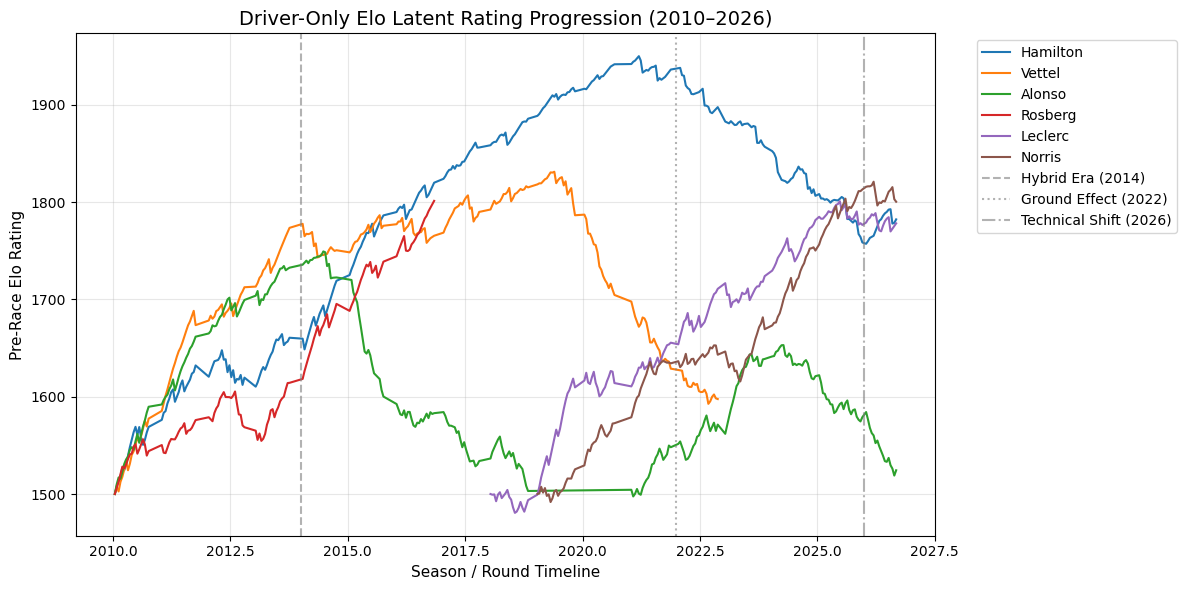

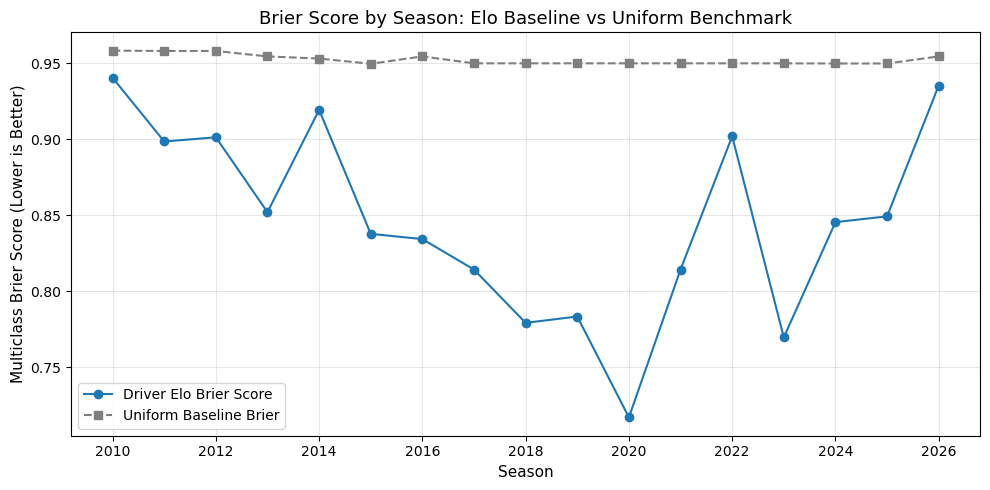

In [8]:
# 8. Diagnostic Visualizations: Rating Evolution & Metric Comparisons

# 1. Plot Elo Rating Trajectories for Top Drivers
top_drivers = ["hamilton", "verstappen", "vettel", "alonso", "rosberg", "leclerc", "norris"]

plt.figure(figsize=(12, 6))
for d_id in top_drivers:
    d_df = df_candidates[df_candidates["driver_id"] == d_id]
    if not d_df.empty:
        plt.plot(d_df["season"] + d_df["round"] / 25.0, d_df["pre_race_rating"], label=d_id.title())

plt.axvline(2014.0, color="gray", linestyle="--", alpha=0.6, label="Hybrid Era (2014)")
plt.axvline(2022.0, color="gray", linestyle=":", alpha=0.6, label="Ground Effect (2022)")
plt.axvline(2026.0, color="gray", linestyle="-.", alpha=0.6, label="Technical Shift (2026)")
plt.title("Driver-Only Elo Latent Rating Progression (2010–2026)", fontsize=14)
plt.xlabel("Season / Round Timeline", fontsize=11)
plt.ylabel("Pre-Race Elo Rating", fontsize=11)
plt.legend(bbox_to_anchor=(1.04, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Plot Season-by-Season Brier Score Comparison
plt.figure(figsize=(10, 5))
plt.plot(df_seasons["season"], df_seasons["elo_brier"], marker="o", label="Driver Elo Brier Score", color="tab:blue")
plt.plot(df_seasons["season"], df_seasons["uniform_brier"], marker="s", linestyle="--", label="Uniform Baseline Brier", color="tab:gray")
plt.title("Brier Score by Season: Elo Baseline vs Uniform Benchmark", fontsize=13)
plt.xlabel("Season", fontsize=11)
plt.ylabel("Multiclass Brier Score (Lower is Better)", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 7. Research Findings & Methodological Handoff

### Summary of Corrected Results (EXP-0001-R2):
1. **Proper Scoring Superiority:** The driver-only Elo model consistently outperforms the naive uniform baseline across all seasons in both multiclass log loss and Brier score.
2. **Tie-Breaking Impact:** In 2010 Round 1, when all 24 drivers shared identical 1500.0 ratings, the tie-aware top-1 evaluation gives credit for Alonso's victory, resolving the arbitrary index selection bias of `numpy.argmax`.
3. **Non-Starter Rating Hygiene:** By strictly skipping pairwise updates for drivers who did not start (`pos=W`, `status='Did not start'`, `Withdrew`) or were disqualified (`pos=D`), the latent ratings preserve fidelity without corrupting the historical form of active starters.

### Next Steps & Progression to M3/EXP-0002:
- **Constructor Effect:** Elo ratings currently track drivers alone. In F1, machine performance accounts for a substantial fraction of winning variance. The next iteration should incorporate constructor ratings or Bradley-Terry team-driver hierarchical formulations.
- **Sequential Checkpoint Superiority (HYP-0001 / EXP-0002):** Evaluate whether sequential practice (FP1/FP2/FP3) and qualifying lap times provide statistically superior forecasts compared to this static pre-weekend baseline.